In [1]:
import psutil
print(f"RAM الكلية: {psutil.virtual_memory().total / 1024**3:.1f} GB")
print(f"عدد الأنوية: {psutil.cpu_count()}")
!df -h /content

RAM الكلية: 12.7 GB
عدد الأنوية: 2
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   21G   88G  20% /


In [2]:
!pip install -q dask[complete] psutil pyarrow
!apt-get -qq install graphviz
!pip install -q graphviz

In [3]:
import numpy as np
import pandas as pd
import os

path = "/content/big_files.csv"
rows_per_chunk = 1_000_000
i = 60
total_rows_written = 0  # متغير لحساب عدد الأسطر الفعلي

# دالة مساعدة لجلب حجم الملف safely (ترجع 0 إذا لم يكن الملف موجوداً)
def get_file_size(file_path):
    return os.path.getsize(file_path) if os.path.exists(file_path) else 0

# الشرط يعتمد على الدالة المساعدة لتجنب خطأ FileNotFound
while get_file_size(path) < 5.5 * 1024**3:
    df = pd.DataFrame({
        "id": np.arange(i*rows_per_chunk, (i+1)*rows_per_chunk),
        "value": np.random.rand(rows_per_chunk) * 100,
        "price": np.random.randint(1, 10_000, rows_per_chunk),
        "category": np.random.choice(list("ABCDE"), rows_per_chunk),
        "text": np.random.choice(["alpha", "beta", "gamma", "delta"], rows_per_chunk),
    })

    # كتابة الـ Header فقط إذا كان الملف غير موجود (أي في المرة الأولى)
    write_header = not os.path.exists(path)

    # الإلحاق
    df.to_csv(path, mode="a", header=write_header, index=False)

    total_rows_written += rows_per_chunk
    i += 1

print(f"الحجم: {os.path.getsize(path) / 1024**3:.2f} GB | الأسطر: {total_rows_written:,}")

الحجم: 5.51 GB | الأسطر: 146,000,000


In [2]:
import pandas as pd

path = "/content/big_files.csv"
sample = pd.read_csv(path, nrows=1_000_000)
mem_mb = sample.memory_usage(deep=True).sum() / 1024**2
est_gb = mem_mb * 148 / 1024

print(f"مليون سطر يشغل: {mem_mb:.0f} MB في الذاكرة")
print(f"الملف الكامل (148M سطر) يحتاج تقريباً: {est_gb:.1f} GB")
del sample

مليون سطر يشغل: 122 MB في الذاكرة
الملف الكامل (148M سطر) يحتاج تقريباً: 17.6 GB


In [ ]:
import resource, psutil, pandas as pd

proc = psutil.Process()
vms = proc.memory_info().vms
limit = vms + 3 * 1024**3
resource.setrlimit(resource.RLIMIT_AS, (limit, limit))

print(f"RAM قبل: {psutil.virtual_memory().percent}%")
try:
    df = pd.read_csv(path)
except MemoryError as e:
    print(" MemoryError:", repr(e))
print(f"RAM بعد: {psutil.virtual_memory().percent}%")

RAM قبل: 11.7%
 MemoryError: MemoryError((131072,), dtype('int64'))
RAM بعد: 11.9%


In [ ]:
import pandas as pd, time, psutil, os, json

path = "/content/big_file.csv"
proc = psutil.Process(os.getpid())

total_sum, total_count = 0.0, 0
cat_counts = {}
peak_mb, n_chunks = 0, 0

t0 = time.perf_counter()
for chunk in pd.read_csv(path, chunksize=100_000):
    total_sum += chunk["value"].sum()
    total_count += chunk["value"].count()
    for k, v in chunk["category"].value_counts().items():
        cat_counts[k] = cat_counts.get(k, 0) + v
    peak_mb = max(peak_mb, proc.memory_info().rss / 1024**2)
    n_chunks += 1
t_chunk = time.perf_counter() - t0

mean_chunk = total_sum / total_count
print(f"عدد الأجزاء: {n_chunks:,} | الأسطر: {total_count:,}")
print(f"المجموع: {total_sum:,.2f} | المتوسط العام: {mean_chunk:.4f}")
print(f"توزيع category: {cat_counts}")
print(f"الزمن: {t_chunk:.1f}s | ذروة الذاكرة: {peak_mb:.0f} MB")

with open("/content/results_chunk.json", "w") as f:
    json.dump({"time_s": t_chunk, "peak_mb": peak_mb, "mean": mean_chunk}, f)

عدد الأجزاء: 1,480 | الأسطر: 148,000,000
المجموع: 7,400,178,615.63 | المتوسط العام: 50.0012
توزيع category: {'D': 29598994, 'B': 29600788, 'A': 29595310, 'C': 29596497, 'E': 29608411}
الزمن: 123.8s | ذروة الذاكرة: 185 MB


In [ ]:
!pip install -q "dask[complete]" psutil pyarrow graphviz
!apt-get -qq install graphviz

In [ ]:
import dask.dataframe as dd
import time, json

path = "/content/big_file.csv"
ddf = dd.read_csv(path, blocksize="128MB")
print("عدد الأجزاء (partitions):", ddf.npartitions)

result = ddf["value"].mean()
print(type(result))

عدد الأجزاء (partitions): 46
<class 'dask.dataframe.dask_expr._collection.Scalar'>


In [ ]:
from dask.diagnostics import ProgressBar, ResourceProfiler

t0 = time.perf_counter()
with ProgressBar(), ResourceProfiler(dt=0.5) as rprof:
    mean_dask = result.compute()
t_dask = time.perf_counter() - t0
peak_dask = max(r.mem for r in rprof.results)

print(f"المتوسط: {mean_dask:.4f}")
print(f"الزمن: {t_dask:.1f}s | ذروة الذاكرة: {peak_dask:.0f} MB")

with open("/content/results_dask.json", "w") as f:
    json.dump({"time_s": t_dask, "peak_mb": peak_dask, "mean": float(mean_dask)}, f)

[########################################] | 100% Completed | 100.80 s
المتوسط: 50.0012
الزمن: 102.4s | ذروة الذاكرة: 1787 MB


In [ ]:
ddf_opt = dd.read_csv(
    path,
    usecols=["value", "category"],
    dtype={"value": "float32", "category": "category"},
    blocksize="128MB",
)

t0 = time.perf_counter()
with ProgressBar(), ResourceProfiler(dt=0.5) as rprof2:

    import dask
    mean_v, max_v, counts = dask.compute(
        ddf_opt["value"].mean(),
        ddf_opt["value"].max(),
        ddf_opt["category"].value_counts(),
    )
t_opt = time.perf_counter() - t0
peak_opt = max(r.mem for r in rprof2.results)

print(f"المتوسط: {mean_v:.4f} | الأعلى: {max_v:.2f}")
print(counts)
print(f"الزمن: {t_opt:.1f}s | ذروة الذاكرة: {peak_opt:.0f} MB")

[########################################] | 100% Completed | 89.58 s
المتوسط: 50.0012 | الأعلى: 100.00
category
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
B                         29600788
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CATEGORIES__           0
__UNKNOWN_CA

In [ ]:
counts = counts[counts > 0]
print(counts)

category
B    29600788
A    29595310
E    29608411
D    29598994
C    29596497
Name: count, dtype: int64


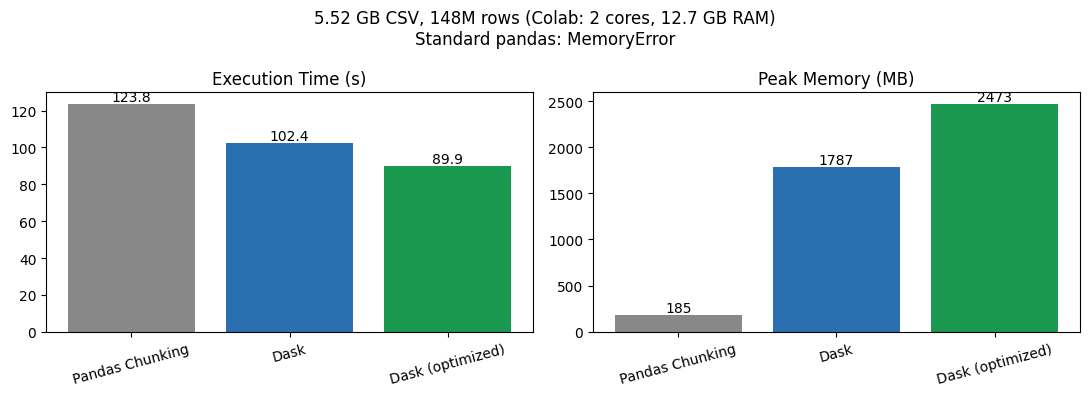

In [ ]:
import matplotlib.pyplot as plt

methods = ["Pandas Chunking", "Dask", "Dask (optimized)"]
times = [123.8, 102.4, 89.9]
mems  = [185, 1787, 2473]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
b1 = ax[0].bar(methods, times, color=["#888", "#2a6fb0", "#1a9850"])
ax[0].set_title("Execution Time (s)"); ax[0].bar_label(b1, fmt="%.1f")
b2 = ax[1].bar(methods, mems, color=["#888", "#2a6fb0", "#1a9850"])
ax[1].set_title("Peak Memory (MB)"); ax[1].bar_label(b2, fmt="%.0f")
for a in ax: a.tick_params(axis="x", rotation=15)
fig.suptitle("5.52 GB CSV, 148M rows (Colab: 2 cores, 12.7 GB RAM)\nStandard pandas: MemoryError")
plt.tight_layout(); plt.savefig("/content/benchmark.png", dpi=150); plt.show()